# PRAKTIKUM DATA MINING
## Tugas 1 — Eksplorasi Ambang Batas min_support dan min_confidence

- **Mata Kuliah**: Praktikum Data Mining
- **Topik**: Pengaruh Variasi Parameter min_support dan min_confidence pada Pola Asosiasi
- **Dataset**: 60 Transaksi Toko Kelontong (`transactions_arm_praktikum.csv`)
- **Referensi Modul**: *Modul Praktikum Data Mining — Bagian 5.1 (Tugas 1)*


---
## Persiapan Data & Pustaka
Memuat pustaka pendukung, membaca dataset transaksi, dan melakukan transformasi matriks one-hot agar notebook ini dapat dieksekusi secara mandiri (*self-contained*).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# Membaca dataset 60 transaksi
df_raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [x.split(', ') for x in df_raw['Items'].dropna()]

# One-hot encoding
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

# Baseline praktikum (min_support = 0.15)
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)

print(f'Dataset berhasil dimuat: {len(transactions)} transaksi')
print(f'Dimensi matriks one-hot: {df.shape}')
print(f'Baseline min_support=0.15: {len(freq_apriori)} frequent itemsets')


Dataset berhasil dimuat: 60 transaksi
Dimensi matriks one-hot: (60, 12)
Baseline min_support=0.15: 17 frequent itemsets


---
# TUGAS 1 — Eksplorasi Ambang Batas min_support dan min_confidence

### 1.1 Jalankan Apriori dengan min_support = 0.10 dan min_confidence = 0.5
Bandingkan jumlah frequent itemset dan aturan asosiasi dengan hasil Bagian 4.3–4.4.


In [2]:
fi_010 = apriori(df, min_support=0.10, use_colnames=True)
rules_010 = association_rules(fi_010, metric='confidence', min_threshold=0.5)

print(f"Hasil min_support = 0.10:")
print(f"- Jumlah Frequent Itemsets : {len(fi_010)}")
print(f"- Jumlah Aturan Asosiasi   : {len(rules_010)}")

print(f"\nPerbandingan dengan Bagian 4.3 - 4.4 (min_support = 0.15):")
print(f"- Frequent Itemsets : 17 itemsets -> {len(fi_010)} itemsets (bertambah {len(fi_010) - 17})")
print(f"- Aturan Asosiasi   : 18 aturan   -> {len(rules_010)} aturan (bertambah {len(rules_010) - 18})")


Hasil min_support = 0.10:
- Jumlah Frequent Itemsets : 19
- Jumlah Aturan Asosiasi   : 20

Perbandingan dengan Bagian 4.3 - 4.4 (min_support = 0.15):
- Frequent Itemsets : 17 itemsets -> 19 itemsets (bertambah 2)
- Aturan Asosiasi   : 18 aturan   -> 20 aturan (bertambah 2)


### 1.2 Naikkan min_confidence menjadi 0.7 pada Hasil Bagian 4.4 (min_support = 0.15)
Mengidentifikasi berapa aturan yang masih bertahan dan aturan mana saja yang tereliminasi (gugur).


In [3]:
rules_015 = association_rules(freq_apriori, metric='confidence', min_threshold=0.5)
rules_conf07 = rules_015[rules_015['confidence'] >= 0.7].sort_values('confidence', ascending=False)
dropped_rules = rules_015[rules_015['confidence'] < 0.7].sort_values('confidence', ascending=False)

print(f"Dari 18 aturan awal:")
print(f"- Aturan Lolos (Confidence >= 0.7) : {len(rules_conf07)} aturan")
print(f"- Aturan Gugur (Confidence < 0.7)  : {len(dropped_rules)} aturan\n")

print("--- 7 ATURAN YANG LOLOS ---")
display(rules_conf07[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(3))

print("\n--- 11 ATURAN YANG GUGUR ---")
display(dropped_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(3))


Dari 18 aturan awal:
- Aturan Lolos (Confidence >= 0.7) : 7 aturan
- Aturan Gugur (Confidence < 0.7)  : 11 aturan

--- 7 ATURAN YANG LOLOS ---


,antecedents,consequents,support,confidence,lift
13,"frozenset({Mentega, Susu})",frozenset({Roti}),0.183,1.000,3.333
12,"frozenset({Roti, Susu})",frozenset({Mentega}),0.183,0.846,2.986
14,"frozenset({Roti, Mentega})",frozenset({Susu}),0.183,0.846,2.672
3,frozenset({Mentega}),frozenset({Roti}),0.217,0.765,2.549
1,frozenset({Kecap}),frozenset({Mie Instan}),0.150,0.750,2.500
2,frozenset({Roti}),frozenset({Mentega}),0.217,0.722,2.549
8,frozenset({Roti}),frozenset({Susu}),0.217,0.722,2.281



--- 11 ATURAN YANG GUGUR ---


,antecedents,consequents,support,confidence,lift
10,frozenset({Shampo}),frozenset({Sabun}),0.150,0.692,2.769
9,frozenset({Susu}),frozenset({Roti}),0.217,0.684,2.281
7,frozenset({Telur}),frozenset({Mie Instan}),0.167,0.667,2.222
5,frozenset({Mentega}),frozenset({Susu}),0.183,0.647,2.043
17,frozenset({Mentega}),"frozenset({Roti, Susu})",0.183,0.647,2.986
16,frozenset({Roti}),"frozenset({Mentega, Susu})",0.183,0.611,3.333
11,frozenset({Sabun}),frozenset({Shampo}),0.150,0.600,2.769
15,frozenset({Susu}),"frozenset({Roti, Mentega})",0.183,0.579,2.672
4,frozenset({Susu}),frozenset({Mentega}),0.183,0.579,2.043
6,frozenset({Mie Instan}),frozenset({Telur}),0.167,0.556,2.222


### 1.3 Grafik Sweep Ambang Batas min_confidence
Melakukan sweep `min_confidence = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]` pada `min_support = 0.15`.


min_confidence = 0.5 : 18 aturan asosiasi
min_confidence = 0.6 : 14 aturan asosiasi
min_confidence = 0.7 :  7 aturan asosiasi
min_confidence = 0.8 :  3 aturan asosiasi
min_confidence = 0.9 :  1 aturan asosiasi
min_confidence = 1.0 :  1 aturan asosiasi


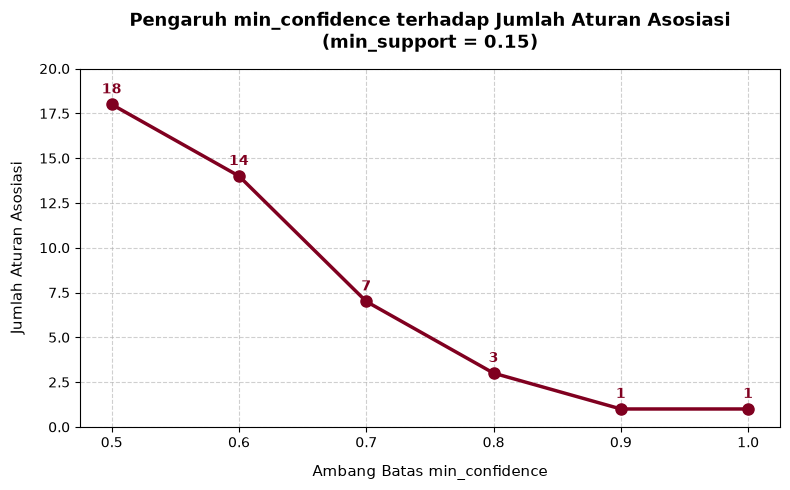

In [4]:
conf_sweep = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
sweep_rule_counts = []

for c in conf_sweep:
    r = association_rules(freq_apriori, metric='confidence', min_threshold=c)
    sweep_rule_counts.append(len(r))
    print(f'min_confidence = {c:.1f} : {len(r):2d} aturan asosiasi')

plt.figure(figsize=(8, 5))
plt.plot(conf_sweep, sweep_rule_counts, marker='o', color='#800020', linewidth=2.5, markersize=8)
plt.title('Pengaruh min_confidence terhadap Jumlah Aturan Asosiasi\n(min_support = 0.15)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Ambang Batas min_confidence', fontsize=11, labelpad=10)
plt.ylabel('Jumlah Aturan Asosiasi', fontsize=11, labelpad=10)
plt.ylim(0, 20)
for x, y in zip(conf_sweep, sweep_rule_counts):
    plt.annotate(f'{y}', (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontweight='bold', color='#800020')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### 1.4 Diskusi Trade-Off Ambang Batas
- **Ambang Batas Rendah (`min_support` & `min_confidence` rendah)**:
  - *Kelebihan*: Menangkap asosiasi antar-produk yang frekuensi penjualannya relatif kecil (niche products / long-tail items), sehingga peluang cross-selling tersembunyi tidak terlewatkan.
  - *Kekurangan*: Menghasilkan aturan dalam jumlah sangat masif, memicu noise, serta banyak aturan dengan korelasi semu (spurious patterns) yang tidak memiliki nilai bisnis praktis.
- **Ambang Batas Tinggi (`min_support` & `min_confidence` tinggi)**:
  - *Kelebihan*: Menjamin aturan yang diperoleh sangat reliabel, didukung oleh data transaksi yang solid, serta memiliki tingkat kepastian prediksi yang tinggi.
  - *Kekurangan*: Sering kali hanya menghasilkan temuan yang sudah bersifat trivial/umum diketahui secara intuitif, serta mengeliminasi pola-pola potensial dari produk bernilai tinggi yang frekuensi penjualannya sedang.
